In [1]:
# First install the extendedjetpy package with: python setup.py install
import numpy as np
import matplotlib as mpl
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
from matplotlib.ticker import LogLocator
from mpl_toolkits.axes_grid1 import make_axes_locatable
import JetCode # CHANGE TO extendedjetpy CUANDO ANDE BIEN!!!!
import smplotlib
import time

In [2]:
def model_syn(E, sigma0, zmax, Lj, a_inj,
              zmax_inj=None, gammaIndex=None, geomIndex_out=None,
              z0=None, fnT=None, facc=None, p=None):
    """
    Total synchrotron SED calculated at photon energies in the vector E.
    The available free parameters are: 
    - sigma0 (initial magnetization) 
    - zmax (jet maximum height)
    - Lj (jet luminosity)
    - a_inj (power injected as Q(z) \propto z^-(1+a_inj) )
    - zmax_inj (jet maximum cell of injection, default: 1e4*R_g)
    - gammaIndex (power law exponent for Gamma(z), default: 0.0016)
    - geomIndex_out (jet opening parameter, default: 0.56)
    - z0 (jet launching reference height, default: 30*R_g)
    - fnT (nonthermal energy fraction, default: 0.1)
    - facc (acceleration efficiency, default: 1e-2)
    - p (power law exponent for Q(E), default: 2.05)
    """
    # Use defaults from system_parameters.f90 if not provided
    if zmax_inj is None:
        zmax_inj = 1e4 * R_g
    if gammaIndex is None:
        gammaIndex = 0.0016
    if geomIndex_out is None:
        geomIndex_out = 0.56
    if z0 is None:
        z0 = 30.0 * R_g
    if fnT is None:
        fnT = 1e-1
    if facc is None:
        facc = 1e-2
    if p is None:
        p = 2.05

    # This routine returns m_data_max values, as defined in global.f90
    fit_values = JetCode.syn_model(sigma0, zmax, Lj, a_inj,
                                   zmax_inj, gammaIndex, geomIndex_out,
                                   z0, fnT, facc, p, E)
    
    # The only useful values are the first ones up to the number of points in E
    return( fit_values[:len(E)])

def model_power(z, sigma0, zmax, Lj, a_inj):    
    """
    Power components as a function of distance z.
    The available free parameters are: 
    - sigma0 (initial magnetization) 
    - Lj (jet luminosity)
    - a_inj (power injected as Q(z) \propto z^-(1+a_inj) )
    """
    
    # This routine returns m_data_max values, as defined in global.f90
    fit_values = JetCode.power_model(sigma0, zmax, Lj, a_inj, z)
    
    # The only useful values are the first ones up to the number of points in z
    return( fit_values[0][:len(z)], fit_values[1][:len(z)], fit_values[2][:len(z)], fit_values[3][:len(z)], fit_values[4][:len(z)], fit_values[5][:len(z)] )

In [3]:
#Decide if include SSC or not
calc_SSC = False

#Constants
mJy = 1.0e-26
dist = 16.8*3.0856e24  # Distance to the source = 16.8 Mpc
h = 6.6260755e-27      # erg s
eV = 1.602176e-12      # eV to erg
a = 4.0*np.pi*dist**2  # Flux dilution factor
M_BH = 6.5e9           # Black hole mass [Msun] (EHT+2018?)
R_g = 1.477e5*M_BH     # Gravitational radius (M_BH [Msun])

# Default model parameters
sigma0_def = 1e2
Lj_def = 1e43
z0_def = 10.0*R_g
a_inj_def = 0.01
zmax_def = 1.1e5*R_g
zmax_inj_def = 1e4*R_g
gammaIndex_def = 0.1
geomIndex_out_def = 0.56
fnT_def = 1e-1
facc_def = 1e-2
p_def = 2.05

# Define the energy range for the SED
E_min = 1e-7 * eV #A 3.3e-7 is prox 100 MHz
if calc_SSC:
    E_max = 2e10 * eV
else:
    E_max = 6e7 * eV

# === Plot parameters ===
xmin, xmax = E_min / h, E_max / h
ymin, ymax = 1e39, 1e42
# Radio range: approximately 1 GHz to 1 THz (1e9 to 1e12 Hz)
radio_min, radio_max = 1e-1, 1e3
flux_radio_min, flux_radio_max = 5e-2, 1e2
    
n_points = 80
E = np.geomspace(E_min, E_max, n_points)
z = np.geomspace(z0_def, zmax_def, n_points)

In [4]:
# Make a list with the values of zmax
a_injs = [-0.99, 0.01, 1.0] # Different injection indices

# Calculate the SED for each zmax value (fixing default parameters)
POWERS = []
for a_inj in a_injs:
    print(f'{a_inj=}')
    POWER = model_power(z, sigma0_def, zmax_def, Lj_def, a_inj)
    time.sleep(1)
    POWERS.append(POWER)

fig, ax = plt.subplots()
for i, a_inj in enumerate(a_injs):
    L_B = POWERS[i][0]
    L_kin = POWERS[i][1]
    L_e = POWERS[i][2]
    L_e_2 = POWERS[i][3]
    L_sy_ = POWERS[i][4]
    L_sy_2 = POWERS[i][5]
    #ax.plot(z/R_g, L_B, label=fr'$L_{{B}}, a_{{\rm inj}}={a_inj}$' if i==0 else "", color='blue', linestyle=['-', '--', ':'][i])
    #ax.plot(z/R_g, L_kin, label=fr'$L_{{\rm kin}}, a_{{\rm inj}}={a_inj}$' if i==0 else "", color='red', linestyle=['-', '--', ':'][i])
    ax.plot(z/R_g, L_e, label=fr'$a_{{\rm inj}}={a_inj}$', color='green', linestyle=['-', '--', ':'][i])
    #ax.plot(z/R_g, L_e_2, label=fr'$a_{{\rm inj}}={a_inj}$', color='orange', linestyle=['-', '--', ':'][i])
    #ax.plot(z/R_g, L_sy_, label=fr'$a_{{\rm inj}}={a_inj}$', color='purple', linestyle=['-', '--', ':'][i])
    ax.plot(z/R_g, L_sy_2, label=fr'$a_{{\rm inj}}={a_inj}$', color='brown', linestyle=['-', '--', ':'][i])
    #ax.plot(z/R_g, L_B+L_kin+L_e, label=fr'$a_{{\rm inj}}={a_inj}$')
ax.set_xscale('log')
ax.set_yscale('log')
ax.set_xlabel(r'$z/R_g$')
ax.set_ylabel(r'Power (erg s$^{-1}$)')
ax.set_title('Jet power components')
ax.legend()
plt.show()

a_inj=-0.99
a_inj=0.01
a_inj=1.0


<Figure size 720x720 with 1 Axes>

a_inj=-0.5
a_inj=0.01
a_inj=0.5
a_inj=0.99
Lum =  9.673328656371017e+41
Lum =  7.040285270167576e+41
Lum =  5.370882161355341e+41
Lum =  4.698766275710459e+41


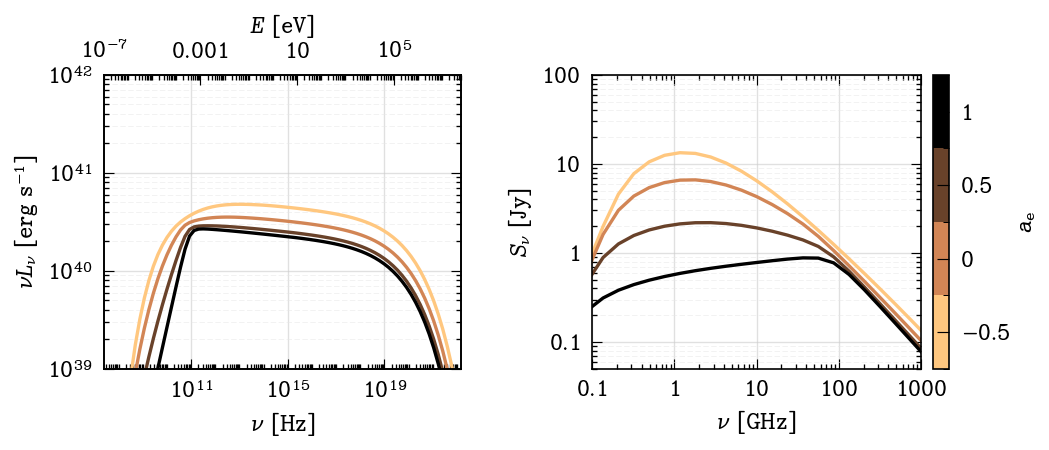

In [5]:
# Make a list with the values of a_inj 
a_injs = [-0.5, 0.01, 0.5, 0.99]
a_inj_labels = [-0.5, 0, 0.5, 1]
# Calculate the SED for each a_inj (fixing default parameters)

SEDs_a_inj = []
for a_inj in a_injs:
    print(f'{a_inj=}')
    SED = model_syn(E, sigma0_def, 1.1e5*R_g, Lj_def, a_inj,
                    zmax_inj=zmax_inj_def, gammaIndex=gammaIndex_def,
                    geomIndex_out=geomIndex_out_def, z0=z0_def,
                    fnT=fnT_def, facc=facc_def, p=p_def)
    time.sleep(1)
    SEDs_a_inj.append(SED)

# === Figure setup ===
fig, (ax, ax_radio) = plt.subplots(1, 2, figsize=(9, 4))

# === Discrete colormap ===
n = len(a_injs)
cmap = mpl.colormaps['copper_r'].resampled(n)
colors = cmap(np.linspace(0, 1, n))

# Discrete colorbar setup
bounds = np.arange(0.5, n + 1.5)
norm = mpl.colors.BoundaryNorm(bounds, cmap.N)
sm = plt.cm.ScalarMappable(norm=norm, cmap=cmap)

# === LEFT PLOT: Full SED ===
for i in range(n):
    ax.plot(E/h, E * SEDs_a_inj[i] * a, color=colors[i], lw=2, label='')
    print("Lum = ", np.trapz(SEDs_a_inj[i]*a, E))

# Scales and limits
ax.set_xscale('log')
ax.set_yscale('log')
ax.set_xlim(xmin, xmax)
ax.set_ylim(ymin, ymax)
ax.set_axisbelow(True)

# Labels
ax.set_xlabel(r"$\nu$ [Hz]")
ax.set_ylabel(r"$\nu L_\nu$ [erg s$^{-1}$]")

# Enable minor ticks with explicit settings
minor_subs = np.arange(1.0, 10.0)
ax.xaxis.set_minor_locator(LogLocator(base=10.0, subs=minor_subs, numticks=100))
ax.yaxis.set_minor_locator(LogLocator(base=10.0, subs=minor_subs, numticks=100))
ax.xaxis.set_minor_formatter(mpl.ticker.NullFormatter())
ax.yaxis.set_minor_formatter(mpl.ticker.NullFormatter())
ax.tick_params(direction='in', which='major', right=True, top=True, length=6)
ax.tick_params(direction='in', which='minor', right=True, top=True, length=3, width=0.8)

# Grid: major on both axes, minor only on y-axis
ax.grid(which='major', axis='both', color='0.8', linestyle='-', linewidth=0.8)
ax.grid(which='minor', axis='y', color='0.9', linestyle='--', linewidth=0.5)

# Twin axis for energy
ax2 = ax.twiny()
ax2.set_xlabel(r"$E$ [eV]")
ax2.set_xlim(E_min / eV, E_max / eV)
ax2.set_xscale('log')
ax2.xaxis.set_minor_locator(LogLocator(base=10.0, subs=minor_subs, numticks=100))
ax2.xaxis.set_minor_formatter(mpl.ticker.NullFormatter())
ax2.tick_params(direction='in', which='major', length=6)
ax2.tick_params(direction='in', which='minor', length=3, width=0.8)

# === RIGHT PLOT: Radio range in mJy ===

for i in range(n):
    # Convert from erg/s to mJy: flux = L_nu / (4 * pi * dist^2)
    # mJy = 1e26 * flux_cgs
    flux_Jy = SEDs_a_inj[i] * h / 1e-23
    ax_radio.plot(E/h / 1e9, flux_Jy, color=colors[i], lw=2)

# Scales and limits
ax_radio.set_xscale('log')
ax_radio.set_yscale('log')
ax_radio.set_xlim(radio_min, radio_max)
ax_radio.set_axisbelow(True)

# Labels
ax_radio.set_xlabel(r"$\nu$ [GHz]")
ax_radio.set_ylabel(r"$S_\nu$ [Jy]")

ax_radio.set_ylim(flux_radio_min, flux_radio_max)

# Enable minor ticks on right plot too
ax_radio.xaxis.set_minor_locator(LogLocator(base=10.0, subs=minor_subs, numticks=100))
ax_radio.yaxis.set_minor_locator(LogLocator(base=10.0, subs=minor_subs, numticks=100))
ax_radio.xaxis.set_minor_formatter(mpl.ticker.NullFormatter())
ax_radio.yaxis.set_minor_formatter(mpl.ticker.NullFormatter())
ax_radio.tick_params(direction='in', which='major', right=True, top=True, length=6)
ax_radio.tick_params(direction='in', which='minor', right=True, top=True, length=3, width=0.8)

# Grid: major on both axes, minor only on y-axis
ax_radio.grid(which='major', axis='both', color='0.8', linestyle='-', linewidth=0.8)
ax_radio.grid(which='minor', axis='y', color='0.9', linestyle='--', linewidth=0.5)

# Colorbar positioned to the right of the right plot without affecting plot size
divider = make_axes_locatable(ax_radio)
cax = divider.append_axes("right", size="5%", pad=0.1)
cbar = fig.colorbar(sm, cax=cax, ticks=np.arange(1, n + 1))
cbar.ax.set_yticklabels(a_inj_labels)
cbar.set_label(r"$a_{\rm e}$")

# === Layout and save ===
plt.tight_layout()
#fig.savefig('SEDs_a_injs.pdf', bbox_inches='tight', pad_inches=0.01)
plt.show()

# Explore zmax variations

In [6]:
# Make a list with the values of zmax
zmaxs = [1.2e5*R_g, 2e5*R_g, 3e5*R_g, 5e5*R_g, 1e7*R_g]#, 5.0, 30.0, 100.0] 

# Calculate the SED for each zmax value (fixing default parameters)
SEDs_zmax = []
for zmax in zmaxs:
    print(f'{zmax/R_g=}')
    SED = model_syn(E, sigma0_def, zmax, Lj_def, a_inj_def,
                    zmax_inj=zmax_inj_def, gammaIndex=gammaIndex_def,
                    geomIndex_out=geomIndex_out_def, z0=z0_def,
                    fnT=fnT_def, facc=facc_def, p=p_def)
    time.sleep(1)
    SEDs_zmax.append(SED)

zmax/R_g=120000.0
zmax/R_g=200000.0
zmax/R_g=300000.0
zmax/R_g=499999.99999999994
zmax/R_g=10000000.000000002


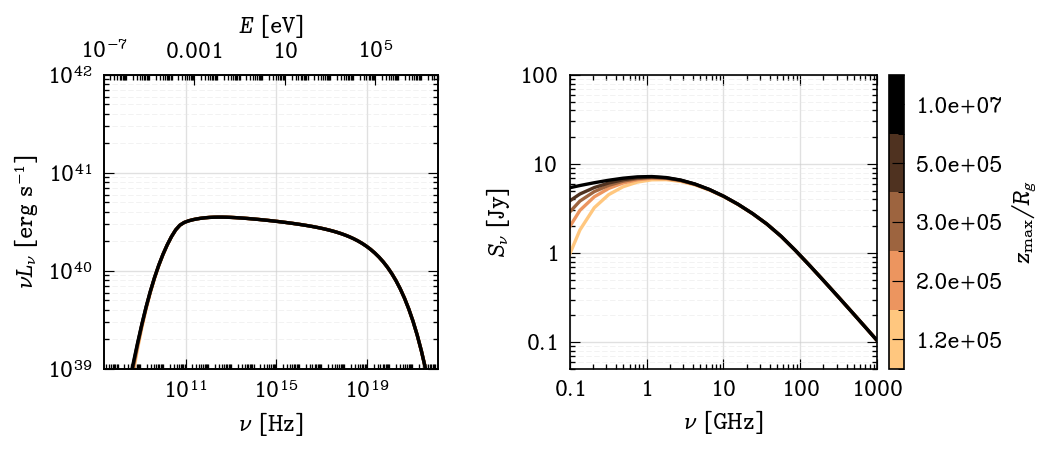

In [7]:
# === Figure setup ===
from mpl_toolkits.axes_grid1 import make_axes_locatable

fig, (ax, ax_radio) = plt.subplots(1, 2, figsize=(9, 4))


# === Discrete colormap ===
n = len(zmaxs)
cmap = mpl.colormaps['copper_r'].resampled(n)
colors = cmap(np.linspace(0, 1, n))

# Discrete colorbar setup
bounds = np.arange(0.5, n + 1.5)
norm = mpl.colors.BoundaryNorm(bounds, cmap.N)
sm = plt.cm.ScalarMappable(norm=norm, cmap=cmap)

# === LEFT PLOT: Full SED ===
for i in range(n):
    ax.plot(E/h, E * SEDs_zmax[i] * a, color=colors[i], lw=2, label='')

# Scales and limits
ax.set_xscale('log')
ax.set_yscale('log')
ax.set_xlim(xmin, xmax)
ax.set_ylim(ymin, ymax)
ax.set_axisbelow(True)

# Labels
ax.set_xlabel(r"$\nu$ [Hz]")
ax.set_ylabel(r"$\nu L_\nu$ [erg s$^{-1}$]")

# Enable minor ticks with explicit settings
minor_subs = np.arange(1.0, 10.0)
ax.xaxis.set_minor_locator(LogLocator(base=10.0, subs=minor_subs, numticks=100))
ax.yaxis.set_minor_locator(LogLocator(base=10.0, subs=minor_subs, numticks=100))
ax.xaxis.set_minor_formatter(mpl.ticker.NullFormatter())
ax.yaxis.set_minor_formatter(mpl.ticker.NullFormatter())
ax.tick_params(direction='in', which='major', right=True, top=True, length=6)
ax.tick_params(direction='in', which='minor', right=True, top=True, length=3, width=0.8)

# Grid: major on both axes, minor only on y-axis
ax.grid(which='major', axis='both', color='0.8', linestyle='-', linewidth=0.8)
ax.grid(which='minor', axis='y', color='0.9', linestyle='--', linewidth=0.5)

# Twin axis for energy
ax2 = ax.twiny()
ax2.set_xlabel(r"$E$ [eV]")
ax2.set_xlim(E_min / eV, E_max /eV)
ax2.set_xscale('log')
ax2.xaxis.set_minor_locator(LogLocator(base=10.0, subs=minor_subs, numticks=100))
ax2.xaxis.set_minor_formatter(mpl.ticker.NullFormatter())
ax2.tick_params(direction='in', which='major', length=6)
ax2.tick_params(direction='in', which='minor', length=3, width=0.8)

# === RIGHT PLOT: Radio range in mJy ===

for i in range(n):
    # Convert from erg/s to mJy: flux = L_nu / (4 * pi * dist^2)
    # mJy = 1e26 * flux_cgs
    flux_Jy = SEDs_zmax[i] * h / 1e-23
    ax_radio.plot(E/h / 1e9, flux_Jy, color=colors[i], lw=2)

# Scales and limits
ax_radio.set_xscale('log')
ax_radio.set_yscale('log')
ax_radio.set_xlim(radio_min, radio_max)
ax_radio.set_axisbelow(True)

# Labels
ax_radio.set_xlabel(r"$\nu$ [GHz]")
ax_radio.set_ylabel(r"$S_\nu$ [Jy]")

ax_radio.set_ylim(flux_radio_min, flux_radio_max)

# Enable minor ticks on right plot too
ax_radio.xaxis.set_minor_locator(LogLocator(base=10.0, subs=minor_subs, numticks=100))
ax_radio.yaxis.set_minor_locator(LogLocator(base=10.0, subs=minor_subs, numticks=100))
ax_radio.xaxis.set_minor_formatter(mpl.ticker.NullFormatter())
ax_radio.yaxis.set_minor_formatter(mpl.ticker.NullFormatter())
ax_radio.tick_params(direction='in', which='major', right=True, top=True, length=6)
ax_radio.tick_params(direction='in', which='minor', right=True, top=True, length=3, width=0.8)

# Grid: major on both axes, minor only on y-axis
ax_radio.grid(which='major', axis='both', color='0.8', linestyle='-', linewidth=0.8)
ax_radio.grid(which='minor', axis='y', color='0.9', linestyle='--', linewidth=0.5)

# Colorbar positioned to the right of the right plot without affecting plot size
divider = make_axes_locatable(ax_radio)
cax = divider.append_axes("right", size="5%", pad=0.1)
cbar = fig.colorbar(sm, cax=cax, ticks=np.arange(1, n + 1))
cbar.ax.set_yticklabels([f'{z/R_g:.1e}' for z in zmaxs])
cbar.set_label(r"$z_{\rm max}/R_g$")

# === Layout and save ===
plt.tight_layout()
fig.savefig('SEDs_zmax.pdf', bbox_inches='tight', pad_inches=0.01)
plt.show()


# Explore sigma0 variations

In [8]:
# Make a list with the values of sigma0
sigma0s = [2.0, 5.0, 30.0, 100.0] 

# Calculate the SED for each sigma0 value (fixing default parameters)
SEDs_sigma0 = []
for sigma0 in sigma0s:
    print(f'{sigma0=}')
    SED = model_syn(E, sigma0, zmax_def, Lj_def, a_inj_def,
                    zmax_inj=zmax_inj_def, gammaIndex=gammaIndex_def,
                    geomIndex_out=geomIndex_out_def, z0=z0_def,
                    fnT=fnT_def, facc=facc_def, p=p_def)
    time.sleep(1)
    SEDs_sigma0.append(SED)

sigma0=2.0
sigma0=5.0
sigma0=30.0
sigma0=100.0


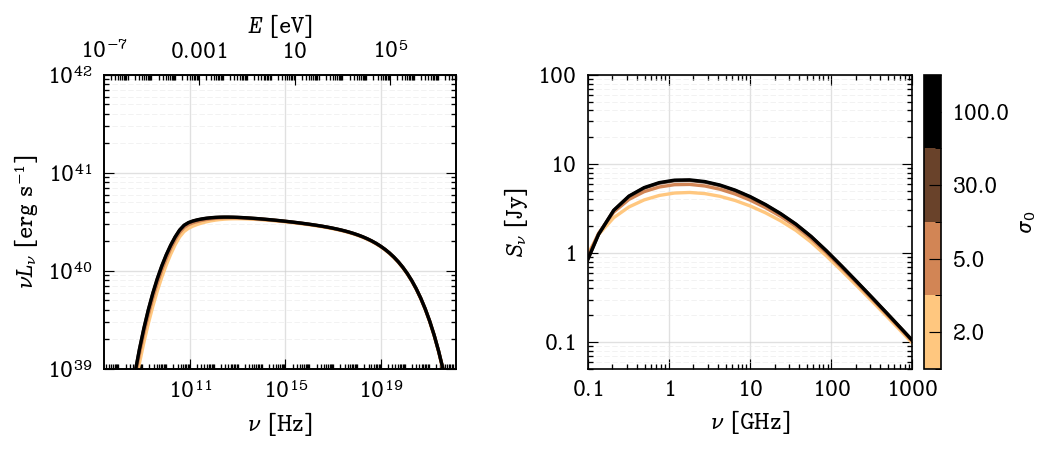

In [9]:
# === Figure setup ===
from mpl_toolkits.axes_grid1 import make_axes_locatable

fig, (ax, ax_radio) = plt.subplots(1, 2, figsize=(9, 4))

# === Discrete colormap ===
n = len(sigma0s)
cmap = mpl.colormaps['copper_r'].resampled(n)
colors = cmap(np.linspace(0, 1, n))

# Discrete colorbar setup
bounds = np.arange(0.5, n + 1.5)
norm = mpl.colors.BoundaryNorm(bounds, cmap.N)
sm = plt.cm.ScalarMappable(norm=norm, cmap=cmap)

# === LEFT PLOT: Full SED ===
for i in range(n):
    ax.plot(E/h, E * SEDs_sigma0[i] * a, color=colors[i], lw=2, label='')

# Scales and limits
ax.set_xscale('log')
ax.set_yscale('log')
ax.set_xlim(xmin, xmax)
ax.set_ylim(ymin, ymax)
ax.set_axisbelow(True)

# Labels
ax.set_xlabel(r"$\nu$ [Hz]")
ax.set_ylabel(r"$\nu L_\nu$ [erg s$^{-1}$]")

# Enable minor ticks with explicit settings
minor_subs = np.arange(1.0, 10.0)
ax.xaxis.set_minor_locator(LogLocator(base=10.0, subs=minor_subs, numticks=100))
ax.yaxis.set_minor_locator(LogLocator(base=10.0, subs=minor_subs, numticks=100))
ax.xaxis.set_minor_formatter(mpl.ticker.NullFormatter())
ax.yaxis.set_minor_formatter(mpl.ticker.NullFormatter())
ax.tick_params(direction='in', which='major', right=True, top=True, length=6)
ax.tick_params(direction='in', which='minor', right=True, top=True, length=3, width=0.8)

# Grid: major on both axes, minor only on y-axis
ax.grid(which='major', axis='both', color='0.8', linestyle='-', linewidth=0.8)
ax.grid(which='minor', axis='y', color='0.9', linestyle='--', linewidth=0.5)

# Twin axis for energy
ax2 = ax.twiny()
ax2.set_xlabel(r"$E$ [eV]")
ax2.set_xlim(E_min / eV, E_max / eV)
ax2.set_xscale('log')
ax2.xaxis.set_minor_locator(LogLocator(base=10.0, subs=minor_subs, numticks=100))
ax2.xaxis.set_minor_formatter(mpl.ticker.NullFormatter())
ax2.tick_params(direction='in', which='major', length=6)
ax2.tick_params(direction='in', which='minor', length=3, width=0.8)

# === RIGHT PLOT: Radio range in mJy ===

for i in range(n):
    # Convert from erg/s to mJy: flux = L_nu / (4 * pi * dist^2)
    # mJy = 1e26 * flux_cgs
    flux_Jy = SEDs_sigma0[i] * h / 1e-23
    ax_radio.plot(E/h / 1e9, flux_Jy, color=colors[i], lw=2)

# Scales and limits
ax_radio.set_xscale('log')
ax_radio.set_yscale('log')
ax_radio.set_xlim(radio_min, radio_max)
ax_radio.set_axisbelow(True)

# Labels
ax_radio.set_xlabel(r"$\nu$ [GHz]")
ax_radio.set_ylabel(r"$S_\nu$ [Jy]")

ax_radio.set_ylim(flux_radio_min, flux_radio_max)

# Enable minor ticks on right plot too
ax_radio.xaxis.set_minor_locator(LogLocator(base=10.0, subs=minor_subs, numticks=100))
ax_radio.yaxis.set_minor_locator(LogLocator(base=10.0, subs=minor_subs, numticks=100))
ax_radio.xaxis.set_minor_formatter(mpl.ticker.NullFormatter())
ax_radio.yaxis.set_minor_formatter(mpl.ticker.NullFormatter())
ax_radio.tick_params(direction='in', which='major', right=True, top=True, length=6)
ax_radio.tick_params(direction='in', which='minor', right=True, top=True, length=3, width=0.8)

# Grid: major on both axes, minor only on y-axis
ax_radio.grid(which='major', axis='both', color='0.8', linestyle='-', linewidth=0.8)
ax_radio.grid(which='minor', axis='y', color='0.9', linestyle='--', linewidth=0.5)

# Colorbar positioned to the right of the right plot without affecting plot size
divider = make_axes_locatable(ax_radio)
cax = divider.append_axes("right", size="5%", pad=0.1)
cbar = fig.colorbar(sm, cax=cax, ticks=np.arange(1, n + 1))
cbar.ax.set_yticklabels(sigma0s)
cbar.set_label(r"$\sigma_0$")

# === Layout and save ===
plt.tight_layout()
fig.savefig('SEDs_sigma0s.pdf', bbox_inches='tight', pad_inches=0.01)
plt.show()


# Explore Ljet variations

In [10]:
# Make a list with the values of Lj 
Ljs = [1e42, 3e42, 1e43, 3e43] 

# Calculate the SED for each Lj (fixing default parameters)
SEDs_Lj = []
for Lj in Ljs:
    print(f'{Lj=}')
    SED = model_syn(E, sigma0_def, zmax_def, Lj, a_inj_def,
                    zmax_inj=zmax_inj_def, gammaIndex=gammaIndex_def,
                    geomIndex_out=geomIndex_out_def, z0=z0_def,
                    fnT=fnT_def, facc=facc_def, p=p_def)
    time.sleep(1)
    SEDs_Lj.append(SED)

Lj=1e+42
Lj=3e+42
Lj=1e+43
Lj=3e+43


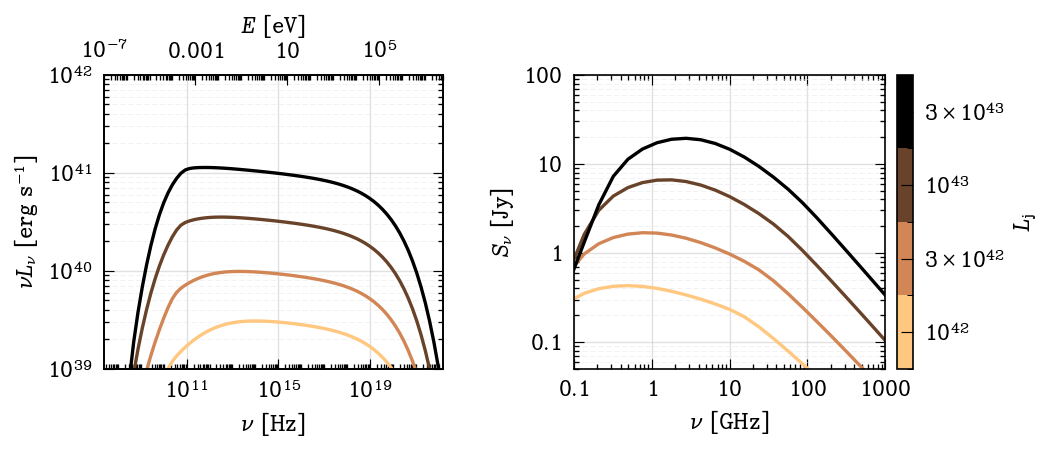

In [11]:
labels = [r'$10^{42}$', r'$3\times10^{42}$', r'$10^{43}$', r'$3\times10^{43}$']

# === Figure setup ===
from mpl_toolkits.axes_grid1 import make_axes_locatable

fig, (ax, ax_radio) = plt.subplots(1, 2, figsize=(9, 4))

# === Discrete colormap ===
n = len(Ljs)
cmap = mpl.colormaps['copper_r'].resampled(n)
colors = cmap(np.linspace(0, 1, n))

# Discrete colorbar setup
bounds = np.arange(0.5, n + 1.5)
norm = mpl.colors.BoundaryNorm(bounds, cmap.N)
sm = plt.cm.ScalarMappable(norm=norm, cmap=cmap)

# === LEFT PLOT: Full SED ===
for i in range(n):
    ax.plot(E/h, E * SEDs_Lj[i] * a, color=colors[i], lw=2, label='')

# Scales and limits
ax.set_xscale('log')
ax.set_yscale('log')
ax.set_xlim(xmin, xmax)
ax.set_ylim(ymin, ymax)
ax.set_axisbelow(True)

# Labels
ax.set_xlabel(r"$\nu$ [Hz]")
ax.set_ylabel(r"$\nu L_\nu$ [erg s$^{-1}$]")

# Enable minor ticks with explicit settings
minor_subs = np.arange(1.0, 10.0)
ax.xaxis.set_minor_locator(LogLocator(base=10.0, subs=minor_subs, numticks=100))
ax.yaxis.set_minor_locator(LogLocator(base=10.0, subs=minor_subs, numticks=100))
ax.xaxis.set_minor_formatter(mpl.ticker.NullFormatter())
ax.yaxis.set_minor_formatter(mpl.ticker.NullFormatter())
ax.tick_params(direction='in', which='major', right=True, top=True, length=6)
ax.tick_params(direction='in', which='minor', right=True, top=True, length=3, width=0.8)

# Grid: major on both axes, minor only on y-axis
ax.grid(which='major', axis='both', color='0.8', linestyle='-', linewidth=0.8)
ax.grid(which='minor', axis='y', color='0.9', linestyle='--', linewidth=0.5)

# Twin axis for energy
ax2 = ax.twiny()
ax2.set_xlabel(r"$E$ [eV]")
ax2.set_xlim(E_min / eV, E_max /eV)
ax2.set_xscale('log')
ax2.xaxis.set_minor_locator(LogLocator(base=10.0, subs=minor_subs, numticks=100))
ax2.xaxis.set_minor_formatter(mpl.ticker.NullFormatter())
ax2.tick_params(direction='in', which='major', length=6)
ax2.tick_params(direction='in', which='minor', length=3, width=0.8)

# === RIGHT PLOT: Radio range in mJy ===

for i in range(n):
    # Convert from erg/s to mJy: flux = L_nu / (4 * pi * dist^2)
    # mJy = 1e26 * flux_cgs
    flux_Jy = SEDs_Lj[i] * h / 1e-23
    ax_radio.plot(E/h / 1e9, flux_Jy, color=colors[i], lw=2)

# Scales and limits
ax_radio.set_xscale('log')
ax_radio.set_yscale('log')
ax_radio.set_xlim(radio_min, radio_max)
ax_radio.set_axisbelow(True)

# Labels
ax_radio.set_xlabel(r"$\nu$ [GHz]")
ax_radio.set_ylabel(r"$S_\nu$ [Jy]")

ax_radio.set_ylim(flux_radio_min, flux_radio_max)

# Enable minor ticks on right plot too
ax_radio.xaxis.set_minor_locator(LogLocator(base=10.0, subs=minor_subs, numticks=100))
ax_radio.yaxis.set_minor_locator(LogLocator(base=10.0, subs=minor_subs, numticks=100))
ax_radio.xaxis.set_minor_formatter(mpl.ticker.NullFormatter())
ax_radio.yaxis.set_minor_formatter(mpl.ticker.NullFormatter())
ax_radio.tick_params(direction='in', which='major', right=True, top=True, length=6)
ax_radio.tick_params(direction='in', which='minor', right=True, top=True, length=3, width=0.8)

# Grid: major on both axes, minor only on y-axis
ax_radio.grid(which='major', axis='both', color='0.8', linestyle='-', linewidth=0.8)
ax_radio.grid(which='minor', axis='y', color='0.9', linestyle='--', linewidth=0.5)

# Colorbar positioned to the right of the right plot without affecting plot size
divider = make_axes_locatable(ax_radio)
cax = divider.append_axes("right", size="5%", pad=0.1)
cbar = fig.colorbar(sm, cax=cax, ticks=np.arange(1, n + 1))
cbar.ax.set_yticklabels(labels)
cbar.set_label(r"$L_{\rm j}$")

# === Layout and save ===
plt.tight_layout()
fig.savefig('SEDs_Ljs.pdf', bbox_inches='tight', pad_inches=0.01)
plt.show()

# Explore z0 variations

In [12]:
# Make a list with the values of z0
z0s = [2*R_g, 10*R_g, 50*R_g, 200*R_g]

# Calculate the SED for each z0 value (fixing default parameters)
SEDs_z0 = []
for z0_val in z0s:
    print(f'{z0_val/R_g=}')
    SED = model_syn(E, sigma0_def, zmax_def, Lj_def, a_inj_def,
                    zmax_inj=zmax_inj_def, gammaIndex=gammaIndex_def,
                    geomIndex_out=geomIndex_out_def, z0=z0_val,
                    fnT=fnT_def, facc=facc_def, p=p_def)
    time.sleep(1)
    SEDs_z0.append(SED)

z0_val/R_g=2.0
z0_val/R_g=10.0
z0_val/R_g=50.0
z0_val/R_g=200.0


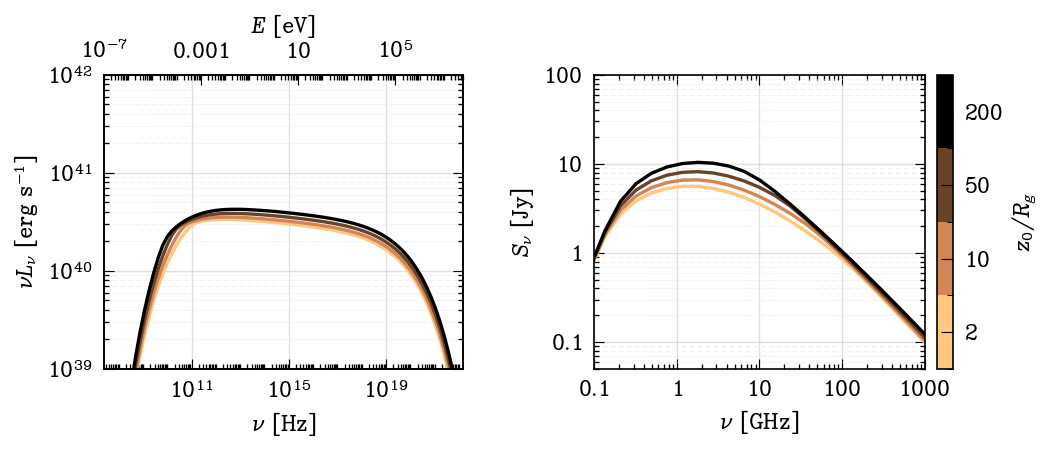

In [13]:
# === Figure setup ===
fig, (ax, ax_radio) = plt.subplots(1, 2, figsize=(9, 4))

# === Discrete colormap ===
n = len(z0s)
cmap = mpl.colormaps['copper_r'].resampled(n)
colors = cmap(np.linspace(0, 1, n))

# Discrete colorbar setup
bounds = np.arange(0.5, n + 1.5)
norm = mpl.colors.BoundaryNorm(bounds, cmap.N)
sm = plt.cm.ScalarMappable(norm=norm, cmap=cmap)

# === LEFT PLOT: Full SED ===
for i in range(n):
    ax.plot(E/h, E * SEDs_z0[i] * a, color=colors[i], lw=2, label='')

ax.set_xscale('log')
ax.set_yscale('log')
ax.set_xlim(xmin, xmax)
ax.set_ylim(ymin, ymax)
ax.set_axisbelow(True)
ax.set_xlabel(r"$\nu$ [Hz]")
ax.set_ylabel(r"$\nu L_\nu$ [erg s$^{-1}$]")

minor_subs = np.arange(1.0, 10.0)
ax.xaxis.set_minor_locator(LogLocator(base=10.0, subs=minor_subs, numticks=100))
ax.yaxis.set_minor_locator(LogLocator(base=10.0, subs=minor_subs, numticks=100))
ax.xaxis.set_minor_formatter(mpl.ticker.NullFormatter())
ax.yaxis.set_minor_formatter(mpl.ticker.NullFormatter())
ax.tick_params(direction='in', which='major', right=True, top=True, length=6)
ax.tick_params(direction='in', which='minor', right=True, top=True, length=3, width=0.8)
ax.grid(which='major', axis='both', color='0.8', linestyle='-', linewidth=0.8)
ax.grid(which='minor', axis='y', color='0.9', linestyle='--', linewidth=0.5)

ax2 = ax.twiny()
ax2.set_xlabel(r"$E$ [eV]")
ax2.set_xlim(E_min / eV, E_max / eV)
ax2.set_xscale('log')
ax2.xaxis.set_minor_locator(LogLocator(base=10.0, subs=minor_subs, numticks=100))
ax2.xaxis.set_minor_formatter(mpl.ticker.NullFormatter())
ax2.tick_params(direction='in', which='major', length=6)
ax2.tick_params(direction='in', which='minor', length=3, width=0.8)

# === RIGHT PLOT: Radio range ===
radio_min, radio_max = 1e-1, 1e3
for i in range(n):
    flux_Jy = SEDs_z0[i] * h / 1e-23
    ax_radio.plot(E/h / 1e9, flux_Jy, color=colors[i], lw=2)

ax_radio.set_xscale('log')
ax_radio.set_yscale('log')
ax_radio.set_xlim(radio_min, radio_max)
ax_radio.set_axisbelow(True)
ax_radio.set_xlabel(r"$\nu$ [GHz]")
ax_radio.set_ylabel(r"$S_\nu$ [Jy]")
ax_radio.set_ylim(flux_radio_min, flux_radio_max)
ax_radio.xaxis.set_minor_locator(LogLocator(base=10.0, subs=minor_subs, numticks=100))
ax_radio.yaxis.set_minor_locator(LogLocator(base=10.0, subs=minor_subs, numticks=100))
ax_radio.xaxis.set_minor_formatter(mpl.ticker.NullFormatter())
ax_radio.yaxis.set_minor_formatter(mpl.ticker.NullFormatter())
ax_radio.tick_params(direction='in', which='major', right=True, top=True, length=6)
ax_radio.tick_params(direction='in', which='minor', right=True, top=True, length=3, width=0.8)
ax_radio.grid(which='major', axis='both', color='0.8', linestyle='-', linewidth=0.8)
ax_radio.grid(which='minor', axis='y', color='0.9', linestyle='--', linewidth=0.5)

divider = make_axes_locatable(ax_radio)
cax = divider.append_axes("right", size="5%", pad=0.1)
cbar = fig.colorbar(sm, cax=cax, ticks=np.arange(1, n + 1))
cbar.ax.set_yticklabels([f'{z/R_g:.0f}' for z in z0s])
cbar.set_label(r"$z_0/R_g$")

plt.tight_layout()
fig.savefig('SEDs_z0s.pdf', bbox_inches='tight', pad_inches=0.01)
plt.show()

# Explore gammaIndex variations

In [14]:
# Make a list with the values of gammaIndex
gammaIndexes = [0.1, 0.3, 0.5]

# Calculate the SED for each gammaIndex value (fixing default parameters)
SEDs_gammaIndex = []
for gI in gammaIndexes:
    print(f'{gI=}')
    SED = model_syn(E, sigma0_def, zmax_def, Lj_def, a_inj_def,
                    zmax_inj=zmax_inj_def, gammaIndex=gI,
                    geomIndex_out=geomIndex_out_def, z0=z0_def,
                    fnT=fnT_def, facc=facc_def, p=p_def)
    time.sleep(1)
    SEDs_gammaIndex.append(SED)

gI=0.1
gI=0.3
gI=0.5


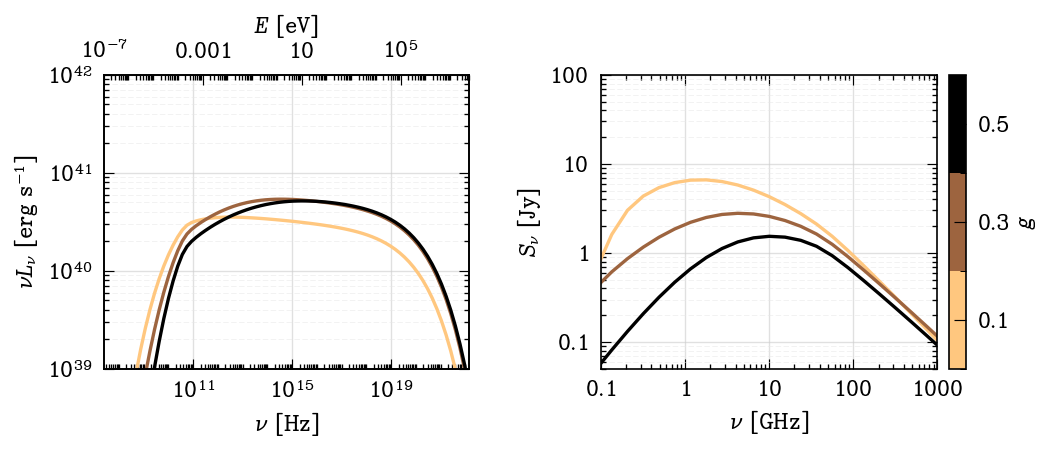

In [15]:
# === Figure setup ===
fig, (ax, ax_radio) = plt.subplots(1, 2, figsize=(9, 4))

# === Discrete colormap ===
n = len(gammaIndexes)
cmap = mpl.colormaps['copper_r'].resampled(n)
colors = cmap(np.linspace(0, 1, n))

bounds = np.arange(0.5, n + 1.5)
norm = mpl.colors.BoundaryNorm(bounds, cmap.N)
sm = plt.cm.ScalarMappable(norm=norm, cmap=cmap)

for i in range(n):
    ax.plot(E/h, E * SEDs_gammaIndex[i] * a, color=colors[i], lw=2, label='')

ax.set_xscale('log')
ax.set_yscale('log')
ax.set_xlim(xmin, xmax)
ax.set_ylim(ymin, ymax)
ax.set_axisbelow(True)
ax.set_xlabel(r"$\nu$ [Hz]")
ax.set_ylabel(r"$\nu L_\nu$ [erg s$^{-1}$]")

minor_subs = np.arange(1.0, 10.0)
ax.xaxis.set_minor_locator(LogLocator(base=10.0, subs=minor_subs, numticks=100))
ax.yaxis.set_minor_locator(LogLocator(base=10.0, subs=minor_subs, numticks=100))
ax.xaxis.set_minor_formatter(mpl.ticker.NullFormatter())
ax.yaxis.set_minor_formatter(mpl.ticker.NullFormatter())
ax.tick_params(direction='in', which='major', right=True, top=True, length=6)
ax.tick_params(direction='in', which='minor', right=True, top=True, length=3, width=0.8)
ax.grid(which='major', axis='both', color='0.8', linestyle='-', linewidth=0.8)
ax.grid(which='minor', axis='y', color='0.9', linestyle='--', linewidth=0.5)

ax2 = ax.twiny()
ax2.set_xlabel(r"$E$ [eV]")
ax2.set_xlim(E_min / eV, E_max / eV)
ax2.set_xscale('log')
ax2.xaxis.set_minor_locator(LogLocator(base=10.0, subs=minor_subs, numticks=100))
ax2.xaxis.set_minor_formatter(mpl.ticker.NullFormatter())
ax2.tick_params(direction='in', which='major', length=6)
ax2.tick_params(direction='in', which='minor', length=3, width=0.8)

for i in range(n):
    flux_Jy = SEDs_gammaIndex[i] * h / 1e-23
    ax_radio.plot(E/h / 1e9, flux_Jy, color=colors[i], lw=2)

ax_radio.set_xscale('log')
ax_radio.set_yscale('log')
ax_radio.set_xlim(radio_min, radio_max)
ax_radio.set_axisbelow(True)
ax_radio.set_xlabel(r"$\nu$ [GHz]")
ax_radio.set_ylabel(r"$S_\nu$ [Jy]")
ax_radio.set_ylim(flux_radio_min, flux_radio_max)
ax_radio.xaxis.set_minor_locator(LogLocator(base=10.0, subs=minor_subs, numticks=100))
ax_radio.yaxis.set_minor_locator(LogLocator(base=10.0, subs=minor_subs, numticks=100))
ax_radio.xaxis.set_minor_formatter(mpl.ticker.NullFormatter())
ax_radio.yaxis.set_minor_formatter(mpl.ticker.NullFormatter())
ax_radio.tick_params(direction='in', which='major', right=True, top=True, length=6)
ax_radio.tick_params(direction='in', which='minor', right=True, top=True, length=3, width=0.8)
ax_radio.grid(which='major', axis='both', color='0.8', linestyle='-', linewidth=0.8)
ax_radio.grid(which='minor', axis='y', color='0.9', linestyle='--', linewidth=0.5)

divider = make_axes_locatable(ax_radio)
cax = divider.append_axes("right", size="5%", pad=0.1)
cbar = fig.colorbar(sm, cax=cax, ticks=np.arange(1, n + 1))
cbar.ax.set_yticklabels(gammaIndexes)
cbar.set_label(r"$g$")

plt.tight_layout()
fig.savefig('SEDs_gammaIndex.pdf', bbox_inches='tight', pad_inches=0.01)
plt.show()

# Explore geomIndex_out variations

In [16]:
# Make a list with the values of geomIndex_out
geomIndexes = [0.25, 0.5, 0.75, 1.0]

# Calculate the SED for each geomIndex_out value (fixing default parameters)
SEDs_geomIndex = []
for gO in geomIndexes:
    print(f'{gO=}')
    SED = model_syn(E, sigma0_def, zmax_def, Lj_def, a_inj_def,
                    zmax_inj=zmax_inj_def, gammaIndex=gammaIndex_def,
                    geomIndex_out=gO, z0=z0_def,
                    fnT=fnT_def, facc=facc_def, p=p_def)
    time.sleep(1)
    SEDs_geomIndex.append(SED)

gO=0.25
gO=0.5
gO=0.75
gO=1.0


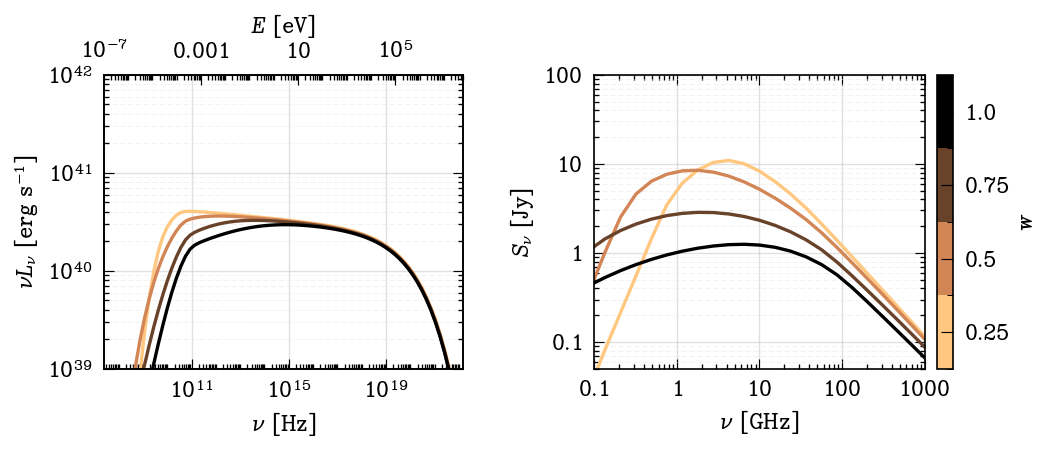

In [17]:

# === Figure setup ===
fig, (ax, ax_radio) = plt.subplots(1, 2, figsize=(9, 4))

n = len(geomIndexes)
cmap = mpl.colormaps['copper_r'].resampled(n)
colors = cmap(np.linspace(0, 1, n))

bounds = np.arange(0.5, n + 1.5)
norm = mpl.colors.BoundaryNorm(bounds, cmap.N)
sm = plt.cm.ScalarMappable(norm=norm, cmap=cmap)

for i in range(n):
    ax.plot(E/h, E * SEDs_geomIndex[i] * a, color=colors[i], lw=2, label='')

ax.set_xscale('log')
ax.set_yscale('log')
ax.set_xlim(xmin, xmax)
ax.set_ylim(ymin, ymax)
ax.set_axisbelow(True)
ax.set_xlabel(r"$\nu$ [Hz]")
ax.set_ylabel(r"$\nu L_\nu$ [erg s$^{-1}$]")

minor_subs = np.arange(1.0, 10.0)
ax.xaxis.set_minor_locator(LogLocator(base=10.0, subs=minor_subs, numticks=100))
ax.yaxis.set_minor_locator(LogLocator(base=10.0, subs=minor_subs, numticks=100))
ax.xaxis.set_minor_formatter(mpl.ticker.NullFormatter())
ax.yaxis.set_minor_formatter(mpl.ticker.NullFormatter())
ax.tick_params(direction='in', which='major', right=True, top=True, length=6)
ax.tick_params(direction='in', which='minor', right=True, top=True, length=3, width=0.8)
ax.grid(which='major', axis='both', color='0.8', linestyle='-', linewidth=0.8)
ax.grid(which='minor', axis='y', color='0.9', linestyle='--', linewidth=0.5)

ax2 = ax.twiny()
ax2.set_xlabel(r"$E$ [eV]")
ax2.set_xlim(E_min / eV, E_max / eV)
ax2.set_xscale('log')
ax2.xaxis.set_minor_locator(LogLocator(base=10.0, subs=minor_subs, numticks=100))
ax2.xaxis.set_minor_formatter(mpl.ticker.NullFormatter())
ax2.tick_params(direction='in', which='major', length=6)
ax2.tick_params(direction='in', which='minor', length=3, width=0.8)

for i in range(n):
    flux_Jy = SEDs_geomIndex[i] * h / 1e-23
    ax_radio.plot(E/h / 1e9, flux_Jy, color=colors[i], lw=2)

ax_radio.set_xscale('log')
ax_radio.set_yscale('log')
ax_radio.set_xlim(radio_min, radio_max)
ax_radio.set_axisbelow(True)
ax_radio.set_xlabel(r"$\nu$ [GHz]")
ax_radio.set_ylabel(r"$S_\nu$ [Jy]")
ax_radio.set_ylim(flux_radio_min, flux_radio_max)
ax_radio.xaxis.set_minor_locator(LogLocator(base=10.0, subs=minor_subs, numticks=100))
ax_radio.yaxis.set_minor_locator(LogLocator(base=10.0, subs=minor_subs, numticks=100))
ax_radio.xaxis.set_minor_formatter(mpl.ticker.NullFormatter())
ax_radio.yaxis.set_minor_formatter(mpl.ticker.NullFormatter())
ax_radio.tick_params(direction='in', which='major', right=True, top=True, length=6)
ax_radio.tick_params(direction='in', which='minor', right=True, top=True, length=3, width=0.8)
ax_radio.grid(which='major', axis='both', color='0.8', linestyle='-', linewidth=0.8)
ax_radio.grid(which='minor', axis='y', color='0.9', linestyle='--', linewidth=0.5)

divider = make_axes_locatable(ax_radio)
cax = divider.append_axes("right", size="5%", pad=0.1)
cbar = fig.colorbar(sm, cax=cax, ticks=np.arange(1, n + 1))
cbar.ax.set_yticklabels(geomIndexes)
cbar.set_label(r"$w$")

plt.tight_layout()
fig.savefig('SEDs_geomIndex_out.pdf', bbox_inches='tight', pad_inches=0.01)
plt.show()

# Explore fnT variations

In [18]:
# Make a list with the values of fnT
fnTs = [0.01, 0.05, 0.1, 0.3]

# Calculate the SED for each fnT value (fixing default parameters)
SEDs_fnT = []
for fnT_val in fnTs:
    print(f'{fnT_val=}')
    Lj_val = Lj_def * fnT_def / fnT_val  # Scale Lj to keep the same accretion power
    SED = model_syn(E, sigma0_def, zmax_def, Lj_val, a_inj_def,
                    zmax_inj=zmax_inj_def, gammaIndex=gammaIndex_def,
                    geomIndex_out=geomIndex_out_def, z0=z0_def,
                    fnT=fnT_val, facc=facc_def, p=p_def)
    time.sleep(1)
    SEDs_fnT.append(SED)

fnT_val=0.01
fnT_val=0.05
fnT_val=0.1
fnT_val=0.3


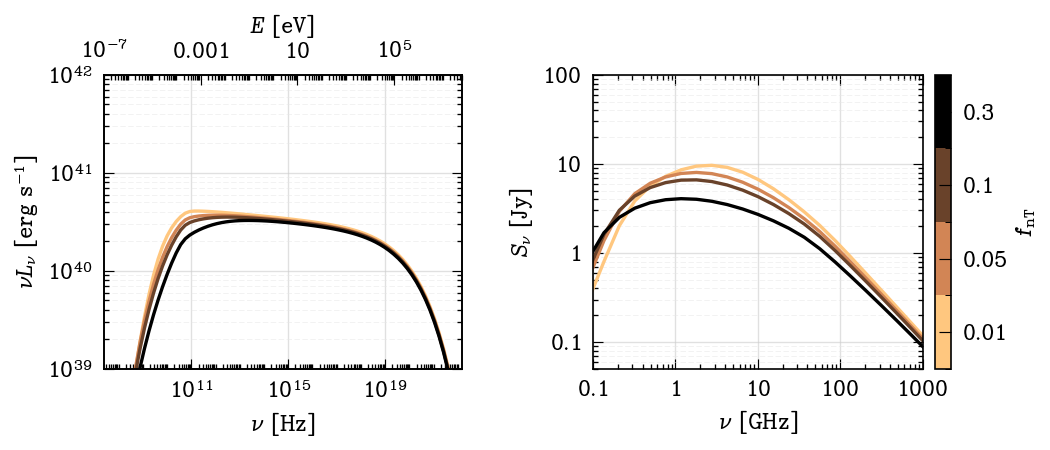

In [19]:
# === Figure setup ===
fig, (ax, ax_radio) = plt.subplots(1, 2, figsize=(9, 4))

n = len(fnTs)
cmap = mpl.colormaps['copper_r'].resampled(n)
colors = cmap(np.linspace(0, 1, n))

bounds = np.arange(0.5, n + 1.5)
norm = mpl.colors.BoundaryNorm(bounds, cmap.N)
sm = plt.cm.ScalarMappable(norm=norm, cmap=cmap)

for i in range(n):
    ax.plot(E/h, E * SEDs_fnT[i] * a, color=colors[i], lw=2, label='')

ax.set_xscale('log')
ax.set_yscale('log')
ax.set_xlim(xmin, xmax)
ax.set_ylim(ymin, ymax)
ax.set_axisbelow(True)
ax.set_xlabel(r"$\nu$ [Hz]")
ax.set_ylabel(r"$\nu L_\nu$ [erg s$^{-1}$]")

minor_subs = np.arange(1.0, 10.0)
ax.xaxis.set_minor_locator(LogLocator(base=10.0, subs=minor_subs, numticks=100))
ax.yaxis.set_minor_locator(LogLocator(base=10.0, subs=minor_subs, numticks=100))
ax.xaxis.set_minor_formatter(mpl.ticker.NullFormatter())
ax.yaxis.set_minor_formatter(mpl.ticker.NullFormatter())
ax.tick_params(direction='in', which='major', right=True, top=True, length=6)
ax.tick_params(direction='in', which='minor', right=True, top=True, length=3, width=0.8)
ax.grid(which='major', axis='both', color='0.8', linestyle='-', linewidth=0.8)
ax.grid(which='minor', axis='y', color='0.9', linestyle='--', linewidth=0.5)

ax2 = ax.twiny()
ax2.set_xlabel(r"$E$ [eV]")
ax2.set_xlim(E_min / eV, E_max /eV)
ax2.set_xscale('log')
ax2.xaxis.set_minor_locator(LogLocator(base=10.0, subs=minor_subs, numticks=100))
ax2.xaxis.set_minor_formatter(mpl.ticker.NullFormatter())
ax2.tick_params(direction='in', which='major', length=6)
ax2.tick_params(direction='in', which='minor', length=3, width=0.8)

for i in range(n):
    flux_Jy = SEDs_fnT[i] * h / 1e-23
    ax_radio.plot(E/h / 1e9, flux_Jy, color=colors[i], lw=2)

ax_radio.set_xscale('log')
ax_radio.set_yscale('log')
ax_radio.set_xlim(radio_min, radio_max)
ax_radio.set_axisbelow(True)
ax_radio.set_xlabel(r"$\nu$ [GHz]")
ax_radio.set_ylabel(r"$S_\nu$ [Jy]")
ax_radio.set_ylim(flux_radio_min, flux_radio_max)
ax_radio.xaxis.set_minor_locator(LogLocator(base=10.0, subs=minor_subs, numticks=100))
ax_radio.yaxis.set_minor_locator(LogLocator(base=10.0, subs=minor_subs, numticks=100))
ax_radio.xaxis.set_minor_formatter(mpl.ticker.NullFormatter())
ax_radio.yaxis.set_minor_formatter(mpl.ticker.NullFormatter())
ax_radio.tick_params(direction='in', which='major', right=True, top=True, length=6)
ax_radio.tick_params(direction='in', which='minor', right=True, top=True, length=3, width=0.8)
ax_radio.grid(which='major', axis='both', color='0.8', linestyle='-', linewidth=0.8)
ax_radio.grid(which='minor', axis='y', color='0.9', linestyle='--', linewidth=0.5)

divider = make_axes_locatable(ax_radio)
cax = divider.append_axes("right", size="5%", pad=0.1)
cbar = fig.colorbar(sm, cax=cax, ticks=np.arange(1, n + 1))
cbar.ax.set_yticklabels(fnTs)
cbar.set_label(r"$f_{\rm nT}$")

plt.tight_layout()
fig.savefig('SEDs_fnT.pdf', bbox_inches='tight', pad_inches=0.01)
plt.show()

# Explore facc variations

In [20]:
# Make a list with the values of facc
faccs = [1e-5, 1e-4, 1e-3, 1e-2]

# Calculate the SED for each facc value (fixing default parameters)
SEDs_facc = []
for facc_val in faccs:
    print(f'{facc_val=}')
    SED = model_syn(E, sigma0_def, zmax_def, Lj_def, a_inj_def,
                    zmax_inj=zmax_inj_def, gammaIndex=gammaIndex_def,
                    geomIndex_out=geomIndex_out_def, z0=z0_def,
                    fnT=fnT_def, facc=facc_val, p=p_def)
    time.sleep(1)
    SEDs_facc.append(SED)

facc_val=1e-05
facc_val=0.0001
facc_val=0.001
facc_val=0.01


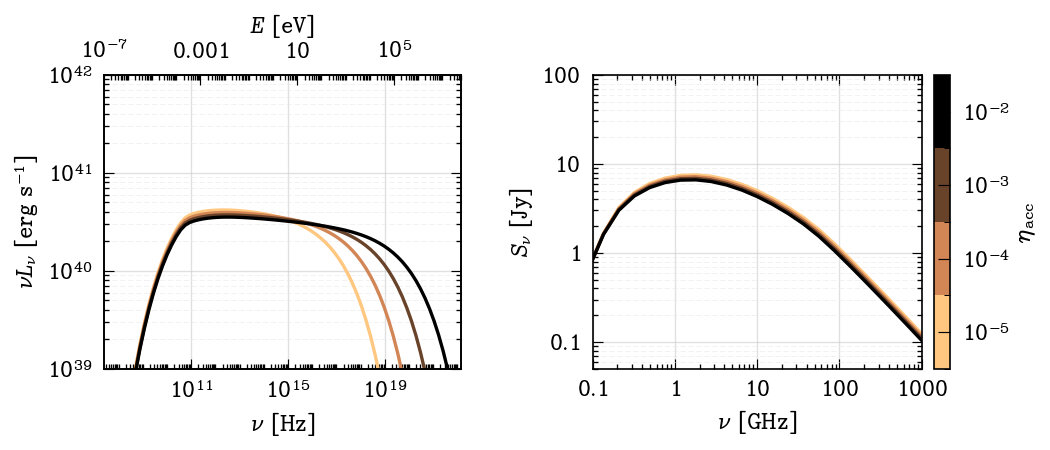

In [21]:
faccs_labels = [r'$10^{-5}$', r'$10^{-4}$', r'$10^{-3}$', r'$10^{-2}$']

# === Figure setup ===
fig, (ax, ax_radio) = plt.subplots(1, 2, figsize=(9, 4))

n = len(faccs)
cmap = mpl.colormaps['copper_r'].resampled(n)
colors = cmap(np.linspace(0, 1, n))

bounds = np.arange(0.5, n + 1.5)
norm = mpl.colors.BoundaryNorm(bounds, cmap.N)
sm = plt.cm.ScalarMappable(norm=norm, cmap=cmap)

for i in range(n):
    ax.plot(E/h, E * SEDs_facc[i] * a, color=colors[i], lw=2, label='')

ax.set_xscale('log')
ax.set_yscale('log')
ax.set_xlim(xmin, xmax)
ax.set_ylim(ymin, ymax)
ax.set_axisbelow(True)
ax.set_xlabel(r"$\nu$ [Hz]")
ax.set_ylabel(r"$\nu L_\nu$ [erg s$^{-1}$]")

minor_subs = np.arange(1.0, 10.0)
ax.xaxis.set_minor_locator(LogLocator(base=10.0, subs=minor_subs, numticks=100))
ax.yaxis.set_minor_locator(LogLocator(base=10.0, subs=minor_subs, numticks=100))
ax.xaxis.set_minor_formatter(mpl.ticker.NullFormatter())
ax.yaxis.set_minor_formatter(mpl.ticker.NullFormatter())
ax.tick_params(direction='in', which='major', right=True, top=True, length=6)
ax.tick_params(direction='in', which='minor', right=True, top=True, length=3, width=0.8)
ax.grid(which='major', axis='both', color='0.8', linestyle='-', linewidth=0.8)
ax.grid(which='minor', axis='y', color='0.9', linestyle='--', linewidth=0.5)

ax2 = ax.twiny()
ax2.set_xlabel(r"$E$ [eV]")
ax2.set_xlim(E_min / eV, E_max /eV)
ax2.set_xscale('log')
ax2.xaxis.set_minor_locator(LogLocator(base=10.0, subs=minor_subs, numticks=100))
ax2.xaxis.set_minor_formatter(mpl.ticker.NullFormatter())
ax2.tick_params(direction='in', which='major', length=6)
ax2.tick_params(direction='in', which='minor', length=3, width=0.8)

for i in range(n):
    flux_Jy = SEDs_facc[i] * h / 1e-23
    ax_radio.plot(E/h / 1e9, flux_Jy, color=colors[i], lw=2)

ax_radio.set_xscale('log')
ax_radio.set_yscale('log')
ax_radio.set_xlim(radio_min, radio_max)
ax_radio.set_axisbelow(True)
ax_radio.set_xlabel(r"$\nu$ [GHz]")
ax_radio.set_ylabel(r"$S_\nu$ [Jy]")
ax_radio.set_ylim(flux_radio_min, flux_radio_max)
ax_radio.xaxis.set_minor_locator(LogLocator(base=10.0, subs=minor_subs, numticks=100))
ax_radio.yaxis.set_minor_locator(LogLocator(base=10.0, subs=minor_subs, numticks=100))
ax_radio.xaxis.set_minor_formatter(mpl.ticker.NullFormatter())
ax_radio.yaxis.set_minor_formatter(mpl.ticker.NullFormatter())
ax_radio.tick_params(direction='in', which='major', right=True, top=True, length=6)
ax_radio.tick_params(direction='in', which='minor', right=True, top=True, length=3, width=0.8)
ax_radio.grid(which='major', axis='both', color='0.8', linestyle='-', linewidth=0.8)
ax_radio.grid(which='minor', axis='y', color='0.9', linestyle='--', linewidth=0.5)

divider = make_axes_locatable(ax_radio)
cax = divider.append_axes("right", size="5%", pad=0.1)
cbar = fig.colorbar(sm, cax=cax, ticks=np.arange(1, n + 1))
cbar.ax.set_yticklabels(faccs_labels)
cbar.set_label(r"$\eta_{\rm acc}$")

plt.tight_layout()
fig.savefig('SEDs_facc.pdf', bbox_inches='tight', pad_inches=0.01)
plt.show()

# Explore p variations

In [22]:
# Make a list with the values of p
ps = [2.01, 2.2, 2.4]

# Calculate the SED for each p value (fixing default parameters)
SEDs_p = []
for p_val in ps:
    print(f'{p_val=}')
    SED = model_syn(E, sigma0_def, zmax_def, Lj_def, a_inj_def,
                    zmax_inj=zmax_inj_def, gammaIndex=gammaIndex_def,
                    geomIndex_out=geomIndex_out_def, z0=z0_def,
                    fnT=fnT_def, facc=facc_def, p=p_val)
    time.sleep(1)
    SEDs_p.append(SED)

p_val=2.01
p_val=2.2
p_val=2.4


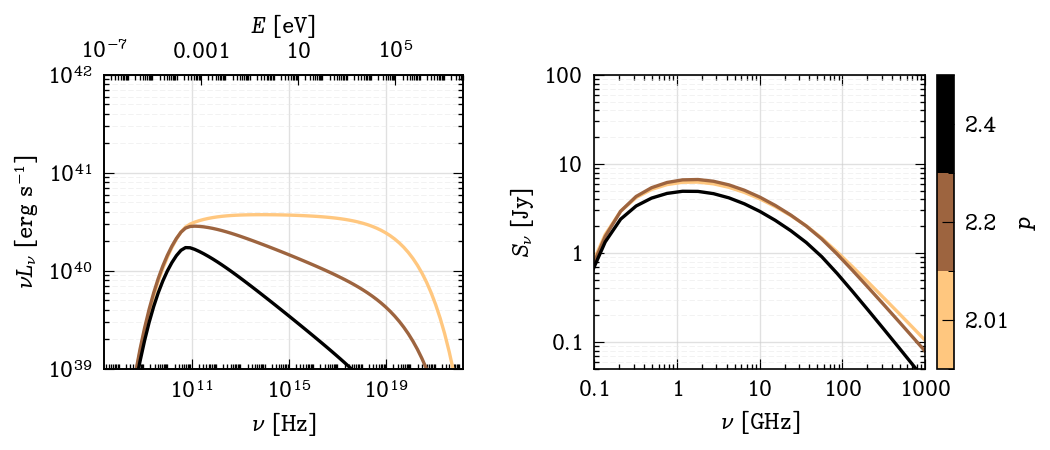

In [23]:
# === Figure setup ===
fig, (ax, ax_radio) = plt.subplots(1, 2, figsize=(9, 4))

n = len(ps)
cmap = mpl.colormaps['copper_r'].resampled(n)
colors = cmap(np.linspace(0, 1, n))

bounds = np.arange(0.5, n + 1.5)
norm = mpl.colors.BoundaryNorm(bounds, cmap.N)
sm = plt.cm.ScalarMappable(norm=norm, cmap=cmap)

for i in range(n):
    ax.plot(E/h, E * SEDs_p[i] * a, color=colors[i], lw=2, label='')

ax.set_xscale('log')
ax.set_yscale('log')
ax.set_xlim(xmin, xmax)
ax.set_ylim(ymin, ymax)
ax.set_axisbelow(True)
ax.set_xlabel(r"$\nu$ [Hz]")
ax.set_ylabel(r"$\nu L_\nu$ [erg s$^{-1}$]")

minor_subs = np.arange(1.0, 10.0)
ax.xaxis.set_minor_locator(LogLocator(base=10.0, subs=minor_subs, numticks=100))
ax.yaxis.set_minor_locator(LogLocator(base=10.0, subs=minor_subs, numticks=100))
ax.xaxis.set_minor_formatter(mpl.ticker.NullFormatter())
ax.yaxis.set_minor_formatter(mpl.ticker.NullFormatter())
ax.tick_params(direction='in', which='major', right=True, top=True, length=6)
ax.tick_params(direction='in', which='minor', right=True, top=True, length=3, width=0.8)
ax.grid(which='major', axis='both', color='0.8', linestyle='-', linewidth=0.8)
ax.grid(which='minor', axis='y', color='0.9', linestyle='--', linewidth=0.5)

ax2 = ax.twiny()
ax2.set_xlabel(r"$E$ [eV]")
ax2.set_xlim(E_min / eV, E_max / eV)
ax2.set_xscale('log')
ax2.xaxis.set_minor_locator(LogLocator(base=10.0, subs=minor_subs, numticks=100))
ax2.xaxis.set_minor_formatter(mpl.ticker.NullFormatter())
ax2.tick_params(direction='in', which='major', length=6)
ax2.tick_params(direction='in', which='minor', length=3, width=0.8)

for i in range(n):
    flux_Jy = SEDs_p[i] * h / 1e-23
    ax_radio.plot(E/h / 1e9, flux_Jy, color=colors[i], lw=2)

ax_radio.set_xscale('log')
ax_radio.set_yscale('log')
ax_radio.set_xlim(radio_min, radio_max)
ax_radio.set_axisbelow(True)
ax_radio.set_xlabel(r"$\nu$ [GHz]")
ax_radio.set_ylabel(r"$S_\nu$ [Jy]")
ax_radio.set_ylim(flux_radio_min, flux_radio_max)
ax_radio.xaxis.set_minor_locator(LogLocator(base=10.0, subs=minor_subs, numticks=100))
ax_radio.yaxis.set_minor_locator(LogLocator(base=10.0, subs=minor_subs, numticks=100))
ax_radio.xaxis.set_minor_formatter(mpl.ticker.NullFormatter())
ax_radio.yaxis.set_minor_formatter(mpl.ticker.NullFormatter())
ax_radio.tick_params(direction='in', which='major', right=True, top=True, length=6)
ax_radio.tick_params(direction='in', which='minor', right=True, top=True, length=3, width=0.8)
ax_radio.grid(which='major', axis='both', color='0.8', linestyle='-', linewidth=0.8)
ax_radio.grid(which='minor', axis='y', color='0.9', linestyle='--', linewidth=0.5)

divider = make_axes_locatable(ax_radio)
cax = divider.append_axes("right", size="5%", pad=0.1)
cbar = fig.colorbar(sm, cax=cax, ticks=np.arange(1, n + 1))
cbar.ax.set_yticklabels(ps)
cbar.set_label(r"$p$")

plt.tight_layout()
fig.savefig('SEDs_p.pdf', bbox_inches='tight', pad_inches=0.01)
plt.show()

# Explore zmax_inj variations

In [24]:
# Make a list with the values of zmax_inj
zmax_injs = [zmax_def/100, zmax_def/10, zmax_def/1.1]

# Calculate the SED for each zmax_inj value (fixing default parameters)
SEDs_zmax_inj = []
for zmax_inj_val in zmax_injs:
    print(f'{zmax_inj_val/R_g=}')
    SED = model_syn(E, sigma0_def, zmax_def, Lj_def, a_inj_def,
                    zmax_inj=zmax_inj_val, gammaIndex=gammaIndex_def,
                    geomIndex_out=geomIndex_out_def, z0=z0_def,
                    fnT=fnT_def, facc=facc_def, p=p_def)
    time.sleep(1)
    SEDs_zmax_inj.append(SED)

zmax_inj_val/R_g=1100.0
zmax_inj_val/R_g=11000.0
zmax_inj_val/R_g=100000.0


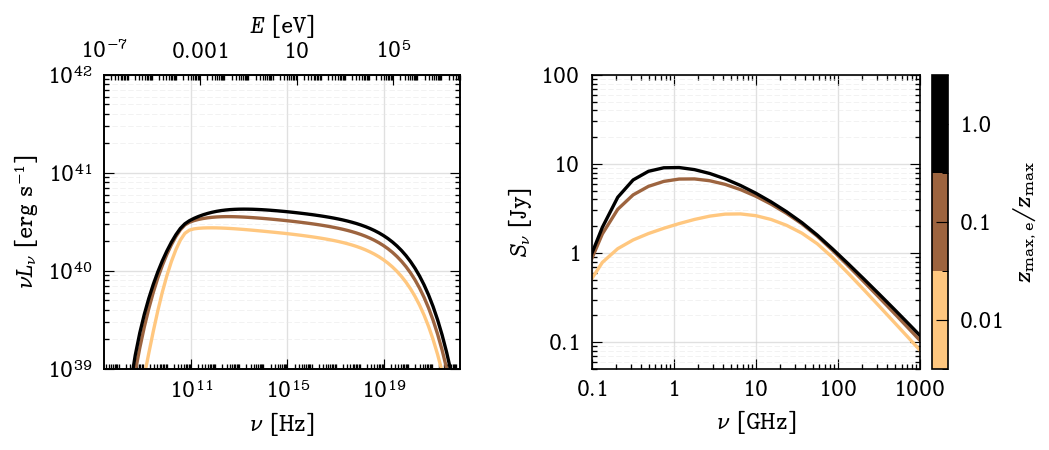

In [25]:
zmax_inj_labels = [1e-2, 1e-1, 1.0]
# === Figure setup ===
fig, (ax, ax_radio) = plt.subplots(1, 2, figsize=(9, 4))

n = len(zmax_injs)
cmap = mpl.colormaps['copper_r'].resampled(n)
colors = cmap(np.linspace(0, 1, n))

bounds = np.arange(0.5, n + 1.5)
norm = mpl.colors.BoundaryNorm(bounds, cmap.N)
sm = plt.cm.ScalarMappable(norm=norm, cmap=cmap)

for i in range(n):
    ax.plot(E/h, E * SEDs_zmax_inj[i] * a, color=colors[i], lw=2, label='')

ax.set_xscale('log')
ax.set_yscale('log')
ax.set_xlim(xmin, xmax)
ax.set_ylim(ymin, ymax)
ax.set_axisbelow(True)
ax.set_xlabel(r"$\nu$ [Hz]")
ax.set_ylabel(r"$\nu L_\nu$ [erg s$^{-1}$]")

minor_subs = np.arange(1.0, 10.0)
ax.xaxis.set_minor_locator(LogLocator(base=10.0, subs=minor_subs, numticks=100))
ax.yaxis.set_minor_locator(LogLocator(base=10.0, subs=minor_subs, numticks=100))
ax.xaxis.set_minor_formatter(mpl.ticker.NullFormatter())
ax.yaxis.set_minor_formatter(mpl.ticker.NullFormatter())
ax.tick_params(direction='in', which='major', right=True, top=True, length=6)
ax.tick_params(direction='in', which='minor', right=True, top=True, length=3, width=0.8)
ax.grid(which='major', axis='both', color='0.8', linestyle='-', linewidth=0.8)
ax.grid(which='minor', axis='y', color='0.9', linestyle='--', linewidth=0.5)

ax2 = ax.twiny()
ax2.set_xlabel(r"$E$ [eV]")
ax2.set_xlim(E_min / eV, E_max /eV)
ax2.set_xscale('log')
ax2.xaxis.set_minor_locator(LogLocator(base=10.0, subs=minor_subs, numticks=100))
ax2.xaxis.set_minor_formatter(mpl.ticker.NullFormatter())
ax2.tick_params(direction='in', which='major', length=6)
ax2.tick_params(direction='in', which='minor', length=3, width=0.8)

for i in range(n):
    flux_Jy = SEDs_zmax_inj[i] * h / 1e-23
    ax_radio.plot(E/h / 1e9, flux_Jy, color=colors[i], lw=2)

ax_radio.set_xscale('log')
ax_radio.set_yscale('log')
ax_radio.set_xlim(radio_min, radio_max)
ax_radio.set_axisbelow(True)
ax_radio.set_xlabel(r"$\nu$ [GHz]")
ax_radio.set_ylabel(r"$S_\nu$ [Jy]")
ax_radio.set_ylim(flux_radio_min, flux_radio_max)
ax_radio.xaxis.set_minor_locator(LogLocator(base=10.0, subs=minor_subs, numticks=100))
ax_radio.yaxis.set_minor_locator(LogLocator(base=10.0, subs=minor_subs, numticks=100))
ax_radio.xaxis.set_minor_formatter(mpl.ticker.NullFormatter())
ax_radio.yaxis.set_minor_formatter(mpl.ticker.NullFormatter())
ax_radio.tick_params(direction='in', which='major', right=True, top=True, length=6)
ax_radio.tick_params(direction='in', which='minor', right=True, top=True, length=3, width=0.8)
ax_radio.grid(which='major', axis='both', color='0.8', linestyle='-', linewidth=0.8)
ax_radio.grid(which='minor', axis='y', color='0.9', linestyle='--', linewidth=0.5)

divider = make_axes_locatable(ax_radio)
cax = divider.append_axes("right", size="5%", pad=0.1)
cbar = fig.colorbar(sm, cax=cax, ticks=np.arange(1, n + 1))
cbar.ax.set_yticklabels(zmax_inj_labels)
cbar.set_label(r"$z_{\rm max,e}/z_{\rm max}$")

plt.tight_layout()
fig.savefig('SEDs_zmax_inj.pdf', bbox_inches='tight', pad_inches=0.01)
plt.show()

In [26]:
# # Make a list with the values of a_inj 
# a_injs = [-1.0, -0.5, 0.01, 0.5, 0.99, 1.5] 
# a_inj_labels = [-1, -0.5, 0.0, 0.5, 1.0, 1.5] 

# a_injs = [-1, 0.01, 0.99]
# # Calculate the SED for each a_inj (fixing default parameters)
# SEDs_a_inj = []
# for a_inj in a_injs:
#     print(f'{a_inj=}')
#     SED = model_syn(E, sigma0_def, zmax_def, Lj_def, a_inj)
#     time.sleep(1)
#     SEDs_a_inj.append(SED)

# # === Figure setup ===
# fig, (ax, ax_radio) = plt.subplots(1, 2, figsize=(9, 4))

# # === Discrete colormap ===
# n = len(a_injs)
# cmap = mpl.colormaps['copper_r'].resampled(n)
# colors = cmap(np.linspace(0, 1, n))

# # Discrete colorbar setup
# bounds = np.arange(0.5, n + 1.5)
# norm = mpl.colors.BoundaryNorm(bounds, cmap.N)
# sm = plt.cm.ScalarMappable(norm=norm, cmap=cmap)

# # === Plot parameters ===
# xmin, xmax = E_min / h, 1e20
# ymin, ymax = 1e38, 1e42

# # === LEFT PLOT: Full SED ===
# for i in range(n):
#     ax.plot(E/h, E * SEDs_a_inj[i] * a, color=colors[i], lw=2, label='')
#     print("Lum = ", np.trapz(SEDs_a_inj[i]*a, E))

# # Scales and limits
# ax.set_xscale('log')
# ax.set_yscale('log')
# ax.set_xlim(xmin, xmax)
# ax.set_ylim(ymin, ymax)
# ax.set_axisbelow(True)

# # Labels
# ax.set_xlabel(r"$\nu$ [Hz]")
# ax.set_ylabel(r"$\nu L_\nu$ [erg s$^{-1}$]")

# # Enable minor ticks with explicit settings
# minor_subs = np.arange(1.0, 10.0)
# ax.xaxis.set_minor_locator(LogLocator(base=10.0, subs=minor_subs, numticks=100))
# ax.yaxis.set_minor_locator(LogLocator(base=10.0, subs=minor_subs, numticks=100))
# ax.xaxis.set_minor_formatter(mpl.ticker.NullFormatter())
# ax.yaxis.set_minor_formatter(mpl.ticker.NullFormatter())
# ax.tick_params(direction='in', which='major', right=True, top=True, length=6)
# ax.tick_params(direction='in', which='minor', right=True, top=True, length=3, width=0.8)

# # Grid: major on both axes, minor only on y-axis
# ax.grid(which='major', axis='both', color='0.8', linestyle='-', linewidth=0.8)
# ax.grid(which='minor', axis='y', color='0.9', linestyle='--', linewidth=0.5)

# # Twin axis for energy
# ax2 = ax.twiny()
# ax2.set_xlabel(r"$E$ [eV]")
# ax2.set_xlim(E_min / eV, h*1e20/eV)
# ax2.set_xscale('log')
# ax2.xaxis.set_minor_locator(LogLocator(base=10.0, subs=minor_subs, numticks=100))
# ax2.xaxis.set_minor_formatter(mpl.ticker.NullFormatter())
# ax2.tick_params(direction='in', which='major', length=6)
# ax2.tick_params(direction='in', which='minor', length=3, width=0.8)

# # === RIGHT PLOT: Radio range in mJy ===
# # Radio range: approximately 1 GHz to 1 THz (1e9 to 1e12 Hz)
# radio_min, radio_max = 1e-1, 1e3

# for i in range(n):
#     # Convert from erg/s to mJy: flux = L_nu / (4 * pi * dist^2)
#     # mJy = 1e26 * flux_cgs
#     flux_Jy = SEDs_a_inj[i] * h / 1e-23
#     ax_radio.plot(E/h / 1e9, flux_Jy, color=colors[i], lw=2)

# # Scales and limits
# ax_radio.set_xscale('log')
# ax_radio.set_yscale('log')
# ax_radio.set_xlim(radio_min, radio_max)
# ax_radio.set_axisbelow(True)

# # Labels
# ax_radio.set_xlabel(r"$\nu$ [GHz]")
# ax_radio.set_ylabel(r"$S_\nu$ [Jy]")

# ax_radio.set_ylim(1e-2, 1e2)

# # Enable minor ticks on right plot too
# ax_radio.xaxis.set_minor_locator(LogLocator(base=10.0, subs=minor_subs, numticks=100))
# ax_radio.yaxis.set_minor_locator(LogLocator(base=10.0, subs=minor_subs, numticks=100))
# ax_radio.xaxis.set_minor_formatter(mpl.ticker.NullFormatter())
# ax_radio.yaxis.set_minor_formatter(mpl.ticker.NullFormatter())
# ax_radio.tick_params(direction='in', which='major', right=True, top=True, length=6)
# ax_radio.tick_params(direction='in', which='minor', right=True, top=True, length=3, width=0.8)

# # Grid: major on both axes, minor only on y-axis
# ax_radio.grid(which='major', axis='both', color='0.8', linestyle='-', linewidth=0.8)
# ax_radio.grid(which='minor', axis='y', color='0.9', linestyle='--', linewidth=0.5)

# # Colorbar positioned to the right of the right plot without affecting plot size
# divider = make_axes_locatable(ax_radio)
# cax = divider.append_axes("right", size="5%", pad=0.1)
# cbar = fig.colorbar(sm, cax=cax, ticks=np.arange(1, n + 1))
# #cbar.ax.set_yticklabels(a_inj_labels)
# cbar.set_label(r"$a_{\rm inj}$")

# # === Layout and save ===
# plt.tight_layout()
# fig.savefig('SEDs_a_injs.pdf', bbox_inches='tight', pad_inches=0.01)
# plt.show()